In [1]:
from google.colab import files
import pandas as pd
import io

In [2]:
uploaded = files.upload()

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [5]:
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

In [6]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Dataset loaded successfully!
Shape: (111, 60)
Columns: ['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [13]:
df.columns = df.columns.astype(str).str.strip()

In [14]:
df = df.melt(
    id_vars=["Country"],
    var_name="year",
    value_name="energy_consumption"
)


In [16]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["energy_consumption"] = pd.to_numeric(
    df["energy_consumption"], errors="coerce"
)


In [17]:
# STEP 4: Select India and handle missing values

country_data = df[
    df["Country"].astype(str).str.strip().str.lower() == "india"
].copy()

In [18]:
country_data = country_data.dropna(
    subset=["year", "energy_consumption"]
)

In [19]:
country_data = country_data.sort_values("year")
country_data = country_data.drop_duplicates(
    subset=["year"], keep="last"
)

In [20]:
country_data = country_data[
    country_data["energy_consumption"] >= 0
].copy()

In [21]:
print("\nSelected Country: India")
print("Available records:", len(country_data))
print(country_data.head())



Selected Country: India
Available records: 59
    Country  year  energy_consumption
91    India  1965                2.23
202   India  1966                2.30
313   India  1967                2.37
424   India  1968                2.53
535   India  1969                2.81


In [22]:
# STEP 5: Check sufficient yearly records

if len(country_data) < 15:
    raise ValueError(
        "Not enough yearly records for reliable LSTM training. "
        "Check the selected country in your dataset."
    )

In [23]:

print("\nYear range:",
      int(country_data["year"].min()),
      "to",
      int(country_data["year"].max()))



Year range: 1965 to 2023


In [25]:
# STEP 6: Normalize energy consumption
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

energy_values = scaler.fit_transform(
    country_data[["energy_consumption"]]
).flatten()

In [26]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [27]:
import numpy as np
import matplotlib.pyplot as plt

In [28]:
# STEP 7: Create sequences using previous 5 years

X = []
y = []

sequence_length = 5

for i in range(sequence_length, len(energy_values)):
    X.append(energy_values[i-5:i])
    y.append(energy_values[i])

X = np.array(X)
y = np.array(y)


In [29]:
X = X.reshape(X.shape[0], X.shape[1], 1)

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)



Input shape: (54, 5, 1)
Output shape: (54,)


In [30]:
# STEP 8: Chronological train-test split (80:20)

split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 43
Testing samples: 11


In [31]:
# STEP 9: Build LSTM model

model = Sequential([
    LSTM(32, input_shape=(5, 1)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# STEP 10: Train the model

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)


In [33]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("\nModel training completed!")


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - loss: 0.0271 - val_loss: 0.2177
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0210 - val_loss: 0.1886
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0144 - val_loss: 0.1583
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0116 - val_loss: 0.1285
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.0075 - val_loss: 0.1005
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0067 - val_loss: 0.0783
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0063 - val_loss: 0.0618
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0072 - val_loss: 0.0508
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0060 - val_loss: 0.0435
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0047 - val_loss: 0.0385
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0050 - val_loss: 0.0362
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0046 - val_lo

In [34]:
# STEP 11: Predict test data

y_pred_scaled = model.predict(X_test)

y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

y_pred_actual = scaler.inverse_transform(
    y_pred_scaled
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 808ms/step


In [35]:
# STEP 12: Evaluate using MAE and RMSE

mae = mean_absolute_error(
    y_test_actual, y_pred_actual
)

rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_pred_actual)
)

print("\nMODEL EVALUATION")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))


MODEL EVALUATION
MAE: 3.0967
RMSE: 3.2734


In [36]:
# STEP 13: Plot actual vs predicted consumption

test_years = country_data["year"].values[
    sequence_length + split:
    sequence_length + split + len(y_test)
]

plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

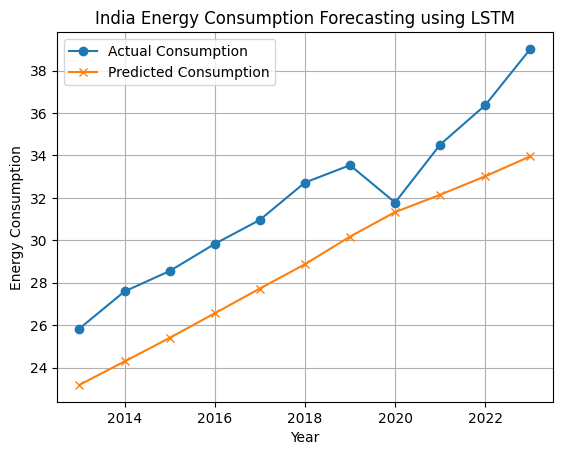

In [37]:
plt.plot(
    test_years,
    y_test_actual.flatten(),
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    test_years,
    y_pred_actual.flatten(),
    marker="x",
    label="Predicted Consumption"
)

plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.title("India Energy Consumption Forecasting using LSTM")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# STEP 14: Predict the next year's consumption

last_five_years = energy_values[-5:].reshape(1, 5, 1)

next_year_scaled = model.predict(last_five_years)

next_year_consumption = scaler.inverse_transform(
    next_year_scaled
)[0][0]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step


In [39]:
last_year = int(country_data["year"].max())

print("\nNEXT YEAR FORECAST")
print("Country: India")
print("Forecast year:", last_year + 1)
print(
    "Predicted energy consumption:",
    round(float(next_year_consumption), 4)
)


NEXT YEAR FORECAST
Country: India
Forecast year: 2024
Predicted energy consumption: 34.9887
